# Wine Quality: MLflow Tracking, Optuna Tuning and a Gated Model Registry

Modified version of [Lab2 in raminmohammadi/MLOps](https://github.com/raminmohammadi/MLOps/tree/main/Labs/Experiment_Tracking_Labs/Mlflow_Labs/Lab2). The full list of changes is in the README.

**Start the tracking server before running this notebook** (separate terminal, repo root, venv active):

```
mlflow server --backend-store-uri sqlite:///mlflow.db --host 127.0.0.1 --port 5000
```

In [1]:
import json
import warnings

import cloudpickle
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import requests
import seaborn as sns
import sklearn
import xgboost as xgb

import mlflow
import mlflow.data
from mlflow import MlflowClient
from mlflow.exceptions import MlflowException
from mlflow.models import infer_signature

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
N_TRIALS = 40
TRACKING_URI = "http://127.0.0.1:5000"
EXPERIMENT_NAME = "wine-quality-optuna"
MODEL_NAME = "wine_quality"
TARGET = "high_quality"

# Public replacement for the private _mlflow_conda_env used in the original
PIP_REQS = [
    f"scikit-learn=={sklearn.__version__}",
    f"xgboost=={xgb.__version__}",
    f"pandas=={pd.__version__}",
    f"cloudpickle=={cloudpickle.__version__}",
]
print("mlflow", mlflow.__version__, "| xgboost", xgb.__version__, "| optuna", optuna.__version__)

Matplotlib is building the font cache; this may take a moment.
c:\Users\Khushal Trivedi\Desktop\MLOps\mlops-mlflow-lab\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


mlflow 3.18.0 | xgboost 3.2.0 | optuna 5.0.0


In [2]:
# Fail early with a clear message if the tracking server is not running
try:
    requests.get(f"{TRACKING_URI}/health", timeout=5).raise_for_status()
except requests.exceptions.RequestException:
    raise RuntimeError("Tracking server not reachable. Start it first: "
                       "mlflow server --backend-store-uri sqlite:///mlflow.db --host 127.0.0.1 --port 5000")

mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)
client = MlflowClient()
print("Connected to", TRACKING_URI)

2026/11/14 16:58:25 INFO mlflow.tracking.fluent: Experiment with name 'wine-quality-optuna' does not exist. Creating a new experiment.


Connected to http://127.0.0.1:5000


## 1. Data

In [3]:
# In this repo the red file is comma-separated and the white file is semicolon-separated
red = pd.read_csv("data/winequality-red.csv")
white = pd.read_csv("data/winequality-white.csv", sep=";")
red["is_red"] = 1
white["is_red"] = 0

raw = pd.concat([red, white], ignore_index=True)
raw.columns = [c.replace(" ", "_") for c in raw.columns]
print("red:", red.shape, "| white:", white.shape, "| combined:", raw.shape)
raw.head()

red: (1599, 13) | white: (4898, 13) | combined: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


In [4]:
# Change from original: drop exact duplicate rows before splitting.
# Otherwise copies of the same wine land in both train and test and inflate AUC.
n_dupes = int(raw.duplicated().sum())
data = raw.drop_duplicates().reset_index(drop=True)
print(f"Removed {n_dupes} duplicate rows: {len(raw)} -> {len(data)}")
print("Missing values:", int(data.isna().sum().sum()))

Removed 1177 duplicate rows: 6497 -> 5320
Missing values: 0


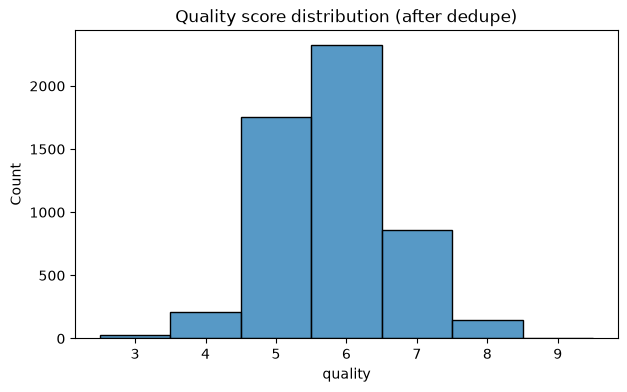

High quality (quality >= 7): 19.0% of rows


In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data["quality"], discrete=True, ax=ax)   # histplot replaces the deprecated distplot
ax.set_title("Quality score distribution (after dedupe)")
plt.show()

data[TARGET] = (data["quality"] >= 7).astype(int)
print(f"High quality (quality >= 7): {data[TARGET].mean():.1%} of rows")

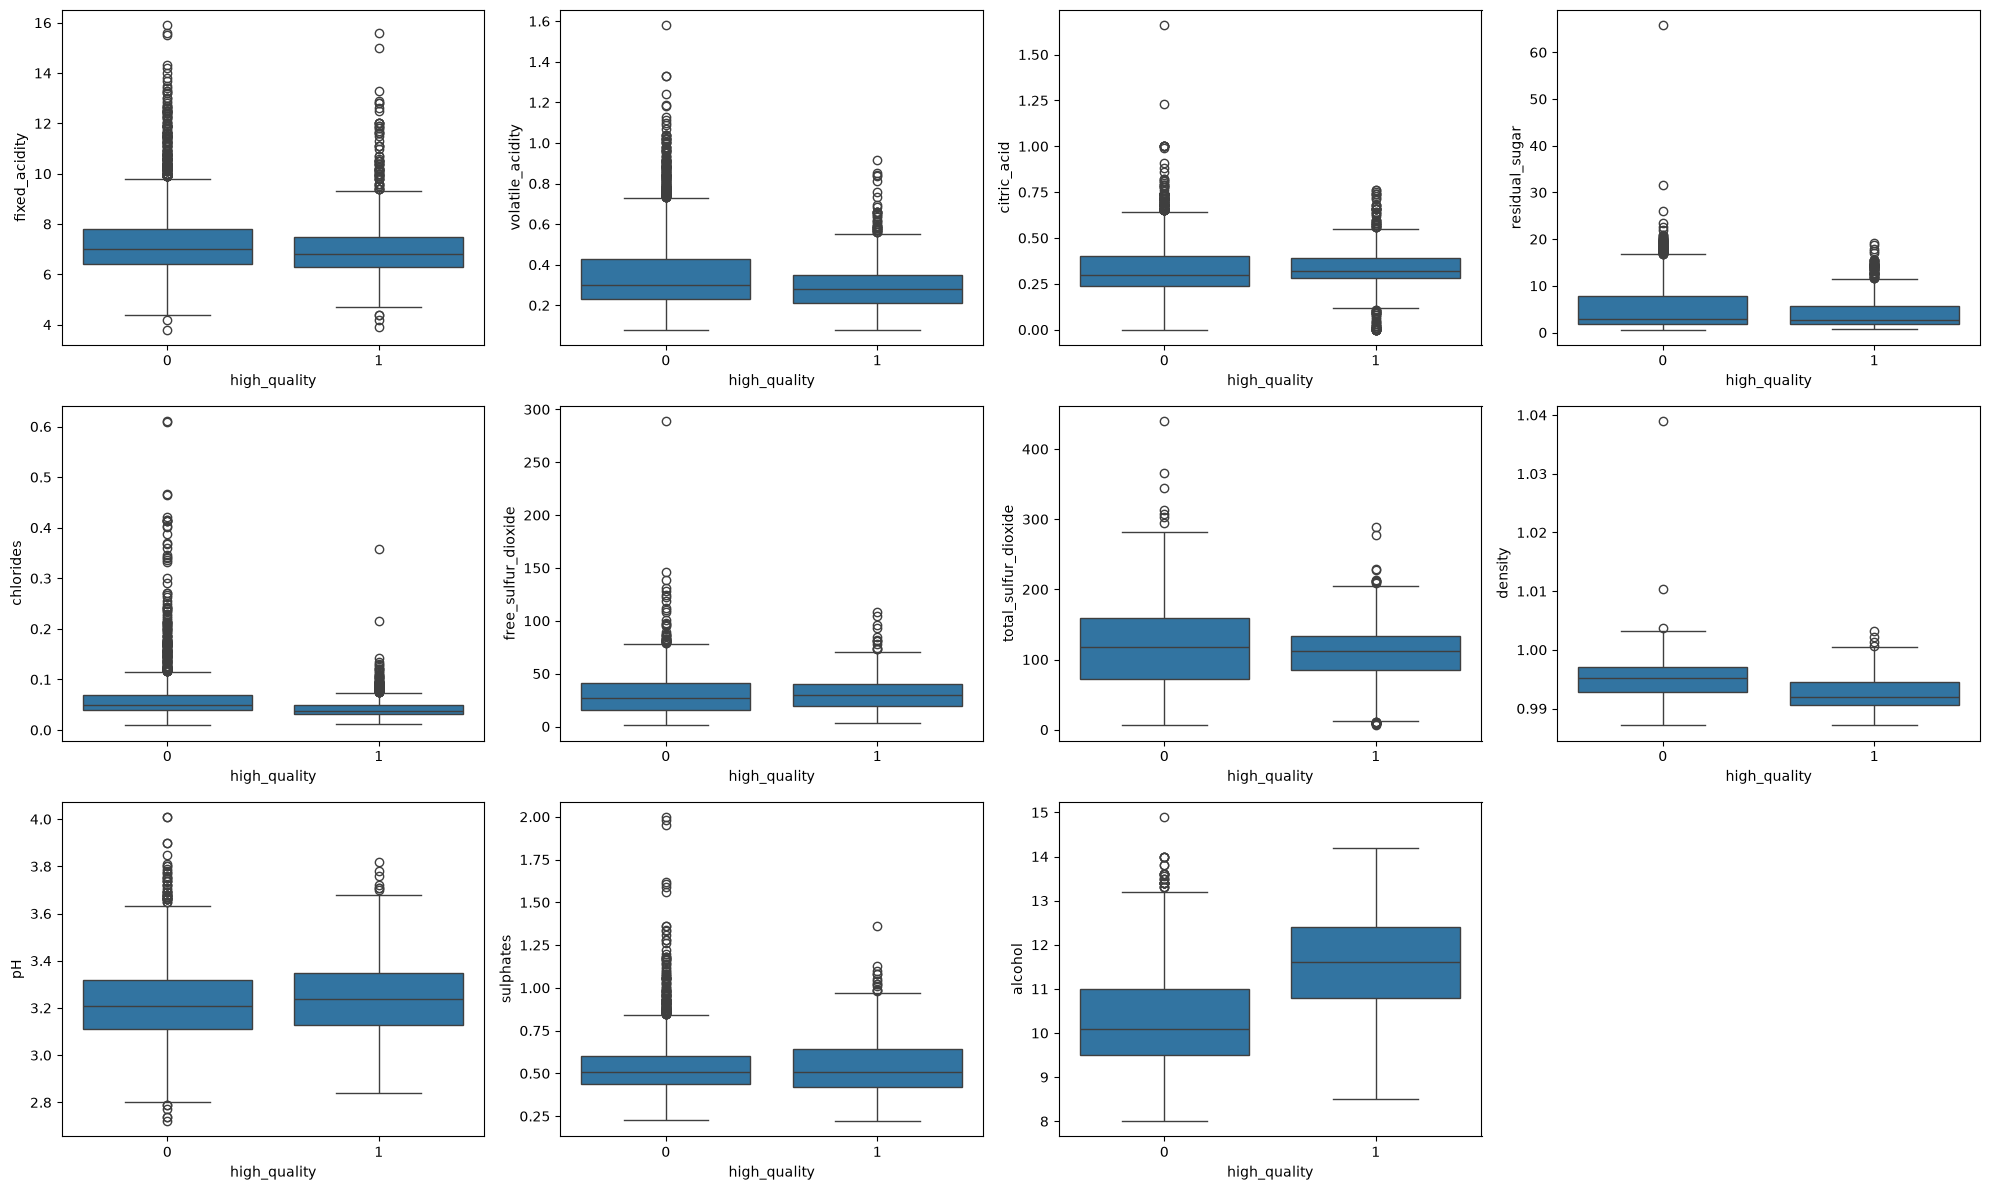

In [6]:
features = [c for c in data.columns if c not in ("quality", TARGET, "is_red")]
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.flat, features):
    sns.boxplot(x=data[TARGET], y=data[col], ax=ax)
    ax.set_xlabel("high_quality")
for ax in axes.flat[len(features):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

In [7]:
X = data.drop(columns=["quality", TARGET])
y = data[TARGET]

# Change from original: stratified 60/20/20 split, since only ~20% of rows are positive
X_train, X_rem, y_train, y_rem = train_test_split(X, y, train_size=0.6, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_rem, y_rem, test_size=0.5, stratify=y_rem, random_state=SEED)

for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s} rows={len(part):5d}  positive={part.mean():.1%}")

# Datasets logged to each run so they show up in the MLflow UI
train_ds = mlflow.data.from_pandas(pd.concat([X_train, y_train], axis=1), name="wine_train", targets=TARGET)
val_ds = mlflow.data.from_pandas(pd.concat([X_val, y_val], axis=1), name="wine_val", targets=TARGET)

train rows= 3192  positive=19.0%
val   rows= 1064  positive=19.0%
test  rows= 1064  positive=19.0%


## 2. Helpers: logging, registration and the promotion gate

Every candidate is scored on the **validation** set. The test set is used once, at the end, on the final champion.

In [8]:
class ProbaModel(mlflow.pyfunc.PythonModel):
    # One wrapper for every model type: returns P(high quality) as a 1-D array
    def __init__(self, model):
        self.model = model

    def predict(self, context, model_input, params=None):
        return self.model.predict_proba(model_input)[:, 1]


def compute_metrics(y_true, proba, split):
    pred = (proba >= 0.5).astype(int)
    return {f"{split}_auc": roc_auc_score(y_true, proba),
            f"{split}_f1": f1_score(y_true, pred),
            f"{split}_accuracy": accuracy_score(y_true, pred)}


def log_eval_plots(model, y_true, proba, split):
    fpr, tpr, _ = roc_curve(y_true, proba)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_true, proba):.3f}")
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set(xlabel="False positive rate", ylabel="True positive rate", title=f"ROC ({split})")
    ax.legend(loc="lower right")
    mlflow.log_figure(fig, f"plots/{split}_roc_curve.png")
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(5, 5))
    ConfusionMatrixDisplay.from_predictions(y_true, (proba >= 0.5).astype(int), ax=ax, colorbar=False)
    ax.set_title(f"Confusion matrix ({split}, threshold 0.5)")
    mlflow.log_figure(fig, f"plots/{split}_confusion_matrix.png")
    plt.close(fig)

    if hasattr(model, "feature_importances_"):
        imp = pd.Series(model.feature_importances_, index=X_train.columns).sort_values()
        fig, ax = plt.subplots(figsize=(6, 5))
        imp.plot.barh(ax=ax)
        ax.set_title("Feature importance")
        fig.tight_layout()
        mlflow.log_figure(fig, "plots/feature_importance.png")
        plt.close(fig)


def log_and_register(model, run_name, params, model_type):
    # Log one fitted model with metrics and plots, then register it as a new version
    proba_val = model.predict_proba(X_val)[:, 1]
    val_metrics = compute_metrics(y_val, proba_val, "val")

    with mlflow.start_run(run_name=run_name):
        mlflow.set_tag("model_type", model_type)
        mlflow.log_input(train_ds, context="training")
        mlflow.log_input(val_ds, context="validation")
        mlflow.log_params({**params, "duplicates_removed": n_dupes})
        mlflow.log_metrics(val_metrics)
        log_eval_plots(model, y_val, proba_val, "val")

        wrapped = ProbaModel(model)
        signature = infer_signature(X_train, wrapped.predict(None, X_train))
        info = mlflow.pyfunc.log_model(name="model", python_model=wrapped, signature=signature,
                                       input_example=X_train.head(3), pip_requirements=PIP_REQS)

    mv = mlflow.register_model(info.model_uri, MODEL_NAME)   # waits until the version is READY
    client.set_model_version_tag(MODEL_NAME, mv.version, "val_auc", f"{val_metrics['val_auc']:.6f}")
    client.set_model_version_tag(MODEL_NAME, mv.version, "model_type", model_type)
    print(f"{run_name}: val_auc={val_metrics['val_auc']:.4f} -> registered as version {mv.version}")
    return mv.version, val_metrics["val_auc"]


def promotion_gate(new_version, new_auc):
    # Challenger becomes champion only if its validation AUC is strictly higher
    client.set_registered_model_alias(MODEL_NAME, "challenger", new_version)
    try:
        champ = client.get_model_version_by_alias(MODEL_NAME, "champion")
        champ_auc = float(champ.tags["val_auc"])
    except MlflowException:
        champ = None

    if champ is None:
        decision, reason = "PROMOTED", "no champion yet"
    elif new_auc > champ_auc:
        decision, reason = "PROMOTED", f"{new_auc:.4f} > champion v{champ.version} ({champ_auc:.4f})"
    else:
        decision, reason = "REJECTED", f"{new_auc:.4f} <= champion v{champ.version} ({champ_auc:.4f})"

    if decision == "PROMOTED":
        client.set_registered_model_alias(MODEL_NAME, "champion", new_version)
        client.delete_registered_model_alias(MODEL_NAME, "challenger")
    client.set_model_version_tag(MODEL_NAME, new_version, "gate_decision", decision)
    print(f"GATE v{new_version}: {decision} ({reason})")
    return decision

c:\Users\Khushal Trivedi\Desktop\MLOps\mlops-mlflow-lab\.venv\Lib\site-packages\mlflow\pyfunc\utils\data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


## 3. Baseline: untuned random forest (same setup as the original, 10 trees)

In [9]:
rf_params = {"n_estimators": 10}
rf = RandomForestClassifier(**rf_params, random_state=SEED).fit(X_train, y_train)
rf_version, rf_auc = log_and_register(rf, "baseline_random_forest", rf_params, "random_forest")
promotion_gate(rf_version, rf_auc)

c:\Users\Khushal Trivedi\Desktop\MLOps\mlops-mlflow-lab\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
c:\Users\Khushal Trivedi\Desktop\MLOps\mlops-mlflow-lab\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot repre

🏃 View run baseline_random_forest at: http://127.0.0.1:5000/#/experiments/1/runs/db1532b739b442a694b1abe9f891c190
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


Successfully registered model 'wine_quality'.
2026/11/14 16:58:40 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: wine_quality, version 1
Created version '1' of model 'wine_quality'.


baseline_random_forest: val_auc=0.8155 -> registered as version 1
GATE v1: PROMOTED (no champion yet)


'PROMOTED'

## 4. XGBoost tuned with Optuna (replaces Hyperopt + SparkTrials)

Runs locally, no Spark or Java needed. Each trial is a nested run under one parent run and logs only params and metrics; only the best configuration gets a logged model, so there is no duplicate model logging.

In [10]:
def make_xgb(p):
    return xgb.XGBClassifier(n_estimators=1000, early_stopping_rounds=50, eval_metric="auc",
                             objective="binary:logistic", tree_method="hist",
                             random_state=SEED, n_jobs=-1, **p)


def objective(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_weight": trial.suggest_float("min_child_weight", 0.5, 10.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 1.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }
    with mlflow.start_run(run_name=f"trial_{trial.number:02d}", nested=True):
        model = make_xgb(params)
        model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
        auc = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])
        mlflow.log_params(params)
        mlflow.log_metrics({"val_auc": auc, "best_iteration": model.best_iteration})
    return auc

In [11]:
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

with mlflow.start_run(run_name="xgb_optuna_search"):
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=N_TRIALS)

    mlflow.log_params({"n_trials": N_TRIALS, "sampler": "TPE"})
    mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()})
    mlflow.log_metrics({"best_val_auc": study.best_value, "best_trial": study.best_trial.number})

    ax = plot_optimization_history(study)
    ax.figure.tight_layout()
    mlflow.log_figure(ax.figure, "optuna/optimization_history.png")
    plt.close(ax.figure)

    ax = plot_param_importances(study)
    ax.figure.tight_layout()
    mlflow.log_figure(ax.figure, "optuna/param_importances.png")
    plt.close(ax.figure)

print(f"Best trial #{study.best_trial.number}: val_auc={study.best_value:.4f}")
study.best_params

🏃 View run trial_00 at: http://127.0.0.1:5000/#/experiments/1/runs/9b48b89e51a34387ad72a287c3fbe8ec
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run trial_01 at: http://127.0.0.1:5000/#/experiments/1/runs/2935f5bfabc14bbbb639399697d73fe2
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run trial_02 at: http://127.0.0.1:5000/#/experiments/1/runs/69b65debfd0549a496b6ac47bdccfc30
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run trial_03 at: http://127.0.0.1:5000/#/experiments/1/runs/e99af748573f4d1da6a8b25fc8aa8471
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run trial_04 at: http://127.0.0.1:5000/#/experiments/1/runs/794f679fe131456ea0b8b65b3d62f4a2
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run trial_05 at: http://127.0.0.1:5000/#/experiments/1/runs/ee4581bb1669405bbdad668c178653a2
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run trial_06 at: http://127.0.0.1

{'max_depth': 10,
 'learning_rate': 0.02776479632653066,
 'subsample': 0.8156735993353891,
 'colsample_bytree': 0.7355808183301813,
 'min_child_weight': 0.7372902552855304,
 'reg_alpha': 0.0271183209510222,
 'reg_lambda': 0.23357950934590815}

In [12]:
# Refit the best configuration, log it with plots, register it and send it through the gate
best_xgb = make_xgb(study.best_params)
best_xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
xgb_version, xgb_auc = log_and_register(best_xgb, "xgb_best", study.best_params, "xgboost")
promotion_gate(xgb_version, xgb_auc)

c:\Users\Khushal Trivedi\Desktop\MLOps\mlops-mlflow-lab\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/14 16:59:32 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may 

🏃 View run xgb_best at: http://127.0.0.1:5000/#/experiments/1/runs/5f1d1fd998dd4d5baf1db7bac738d980
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


Created version '2' of model 'wine_quality'.


xgb_best: val_auc=0.8687 -> registered as version 2
GATE v2: PROMOTED (0.8687 > champion v1 (0.8155))


'PROMOTED'

## 5. Gate check: a deliberately weak model should be rejected

In [13]:
weak_params = {"max_depth": 2}
weak = DecisionTreeClassifier(**weak_params, random_state=SEED).fit(X_train, y_train)
weak_version, weak_auc = log_and_register(weak, "weak_decision_tree", weak_params, "decision_tree")
promotion_gate(weak_version, weak_auc)

c:\Users\Khushal Trivedi\Desktop\MLOps\mlops-mlflow-lab\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/14 17:03:36 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may 

🏃 View run weak_decision_tree at: http://127.0.0.1:5000/#/experiments/1/runs/e493d5da0b5846559f59e2b78e95714f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


Registered model 'wine_quality' already exists. Creating a new version of this model...
2026/11/14 17:03:37 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: wine_quality, version 3
Created version '3' of model 'wine_quality'.


weak_decision_tree: val_auc=0.7736 -> registered as version 3
GATE v3: REJECTED (0.7736 <= champion v2 (0.8687))


'REJECTED'

In [19]:
versions = [client.get_model_version(MODEL_NAME, mv.version)
            for mv in client.search_model_versions(f"name='{MODEL_NAME}'")]
registry = pd.DataFrame([{
    "version": int(mv.version),
    "model_type": mv.tags.get("model_type"),
    "val_auc": float(mv.tags.get("val_auc")),
    "gate_decision": mv.tags.get("gate_decision"),
    "aliases": ", ".join(mv.aliases),
} for mv in versions]).sort_values("version").reset_index(drop=True)
registry

,version,model_type,val_auc,gate_decision,aliases
0,1,random_forest,0.815528,PROMOTED,
1,2,xgboost,0.868668,PROMOTED,champion
2,3,decision_tree,0.773641,REJECTED,challenger


## 6. Final evaluation of the champion on the untouched test set

In [15]:
champ_mv = client.get_model_version_by_alias(MODEL_NAME, "champion")
champion = mlflow.pyfunc.load_model(f"models:/{MODEL_NAME}@champion")
proba_test = np.asarray(champion.predict(X_test))
test_metrics = compute_metrics(y_test, proba_test, "test")

with mlflow.start_run(run_name="champion_test_eval"):
    mlflow.set_tags({"model_version": champ_mv.version, "model_type": champ_mv.tags.get("model_type")})
    mlflow.log_metrics(test_metrics)
    log_eval_plots(None, y_test, proba_test, "test")

client.set_model_version_tag(MODEL_NAME, champ_mv.version, "test_auc", f"{test_metrics['test_auc']:.6f}")
print(f"Champion v{champ_mv.version} ({champ_mv.tags.get('model_type')}):",
      {k: round(v, 4) for k, v in test_metrics.items()})

🏃 View run champion_test_eval at: http://127.0.0.1:5000/#/experiments/1/runs/57dc0850cb6940b18c1a83070c0ee179
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Champion v2 (xgboost): {'test_auc': 0.8493, 'test_f1': 0.3986, 'test_accuracy': 0.8383}


## 7. Batch inference with pandas (replaces the Spark UDF + Delta table)

The test features are written out as an "incoming" file with no labels, scored by whatever version currently holds the `champion` alias, and the predictions are saved and logged as an artifact.

In [16]:
import os
os.makedirs("batch", exist_ok=True)
X_test.to_csv("batch/incoming_wines.csv", index=False)

batch = pd.read_csv("batch/incoming_wines.csv")
scored = batch.copy()
scored["p_high_quality"] = np.asarray(champion.predict(batch))
scored["predicted_high_quality"] = (scored["p_high_quality"] >= 0.5).astype(int)
scored.to_csv("batch/predictions.csv", index=False)

with mlflow.start_run(run_name="batch_inference"):
    mlflow.set_tag("model_version", champ_mv.version)
    mlflow.log_metrics({"rows_scored": len(scored),
                        "share_predicted_high": float(scored["predicted_high_quality"].mean())})
    mlflow.log_artifact("batch/predictions.csv")

print(f"Scored {len(scored)} wines with champion v{champ_mv.version}")
scored.head()

🏃 View run batch_inference at: http://127.0.0.1:5000/#/experiments/1/runs/1fe005bd161a4aaa99e8e2559fbfff87
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Scored 1064 wines with champion v2


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,p_high_quality,predicted_high_quality
0,7.3,0.25,0.27,3.8,0.047,16.0,79.0,0.99173,3.07,0.46,11.3,0,0.213704,0
1,7.1,0.23,0.39,1.6,0.032,12.0,65.0,0.98980,3.25,0.40,12.7,0,0.361916,0
2,6.2,0.57,0.10,2.1,0.048,4.0,11.0,0.99448,3.44,0.76,10.8,1,0.112672,0
3,6.4,0.29,0.44,3.6,0.200,75.0,181.0,0.99420,3.02,0.41,9.1,0,0.024327,0
4,6.9,0.20,0.41,1.1,0.060,36.0,104.0,0.99317,2.99,0.39,9.2,0,0.039464,0


## 8. Real-time serving

In a **new terminal** (repo root, venv active), point the CLI at the tracking server and serve the champion. `--env-manager local` reuses this venv, which avoids the pyenv/virtualenv failure on Windows.

PowerShell:
```
$env:MLFLOW_TRACKING_URI = "http://127.0.0.1:5000"
mlflow models serve -m "models:/wine_quality@champion" --env-manager local --host 127.0.0.1 --port 5001
```
Mac/Linux:
```
export MLFLOW_TRACKING_URI=http://127.0.0.1:5000
mlflow models serve -m "models:/wine_quality@champion" --env-manager local --host 127.0.0.1 --port 5001
```
Wait for the server to report it is listening, then run the next cell.

In [18]:
sample = batch.head(5)
payload = {"dataframe_split": json.loads(sample.to_json(orient="split", index=False))}
resp = requests.post("http://127.0.0.1:5001/invocations", json=payload, timeout=30)
resp.raise_for_status()
served = np.asarray(resp.json()["predictions"], dtype=float)
local = np.asarray(champion.predict(sample), dtype=float)

print("Served:", np.round(served, 4))
print("Local: ", np.round(local, 4))
print("Served predictions match local champion:", np.allclose(served, local))

Served: [0.2137 0.3619 0.1127 0.0243 0.0395]
Local:  [0.2137 0.3619 0.1127 0.0243 0.0395]
Served predictions match local champion: True
